# 1 · Full-text search: a search engine vs. the database you already have

**The question:** Postgres can already search text. How much better is a real search engine, and
what does it give you besides better ranking?

**The test:** SciFact, 5,183 scientific abstracts and expert-labelled questions: 809 for *tuning*
(train) and 300 kept aside for the *final score* (test). Each method returns its top 10 abstracts.

**How the score works:** *nDCG@10* rewards putting the right abstracts near the top of the 10
(1.0 = perfect). *Recall@10* is the share of right abstracts that made the top 10 at all.

In [1]:
%matplotlib inline
import os, json
os.chdir('..')  # run from the project root so data/ and results/ resolve
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from oslab import plot, stack
plot.style()
pd.set_option('display.width', 160)
assert stack.is_up(), 'start the stack first: docker compose up -d'

from oslab import search, tune, features, beir, metrics

## 1 · What the search engine does to text first: analyzers

Before indexing, every text goes through an *analyzer*. The `english` analyzer lowercases, drops
filler words ("the", "of") and *stems* words to a root, so "cells" and "cell" match. Postgres's
`to_tsvector('english', ...)` does the same, so any difference below is about **ranking**.

In [2]:
os_ = stack.opensearch()
text = 'Mesenchymal stem cells are repairing the damaged cartilage'
for analyzer in ('standard', 'english'):
    toks = [t['token'] for t in os_.indices.analyze(body={'analyzer': analyzer, 'text': text})['tokens']]
    print(f'{analyzer:9s}', toks)
print('postgres ', stack.postgres().execute("select to_tsvector('english', %s)", (text,)).fetchone()[0])

standard  ['mesenchymal', 'stem', 'cells', 'are', 'repairing', 'the', 'damaged', 'cartilage']
english   ['mesenchym', 'stem', 'cell', 'repair', 'damag', 'cartilag']
postgres  'cartilag':8 'cell':3 'damag':7 'mesenchym':1 'repair':5 'stem':2


## 2 · First result: OpenSearch vs Postgres, out of the box

Three ways to answer each test question:

- **OpenSearch BM25**: BM25 is the standard ranking formula. Rare words ("mesenchymal") count more
  than common ones, and a word repeated 20 times doesn't count 20 times as much.
- **Postgres, every word must match**: what `websearch_to_tsquery` does: the usual choice for a search box.
- **Postgres, any word may match**, ranked by Postgres's `ts_rank_cd`.

In [3]:
rows = [json.load(open(f'results/scifact-{b}.json')) for b in ('os-bm25', 'pg-or', 'pg-and')]
pd.DataFrame(rows)[['backend', 'ndcg@10', 'recall@10', 'p50_ms', 'empty_results']].round(3)

,backend,ndcg@10,recall@10,p50_ms,empty_results
0,os-bm25,0.610,0.750,1.252,0
1,pg-or,0.368,0.514,79.571,0
2,pg-and,0.072,0.073,0.212,274


**Reading it:** requiring every word is a trap for real questions: **274 of 300 questions return
nothing**, because no abstract contains every word of a long question. Allowing any word fixes that,
but Postgres's ranking is far behind BM25.

## 3 · Tuning, done honestly

BM25 has settings, and so does the query. We tried **640 combinations** on the 809 *train* questions:

- analyzer: `english` vs `standard` (no stemming)
- `k1` (how fast repeated words stop adding score) and `b` (how much long abstracts are penalised)
- how title and body scores combine (`best_fields` = best single field, `most_fields` = add them up,
  `cross_fields` = treat them as one big field) and how much the title counts

The winner was then scored **once** on the 300 test questions. (The sweep takes ~3 minutes:
`python -m oslab tune`; here we load its saved output.)

In [4]:
sweep = pd.read_json('results/tune-train.jsonl', lines=True)
sweep['query_type'] = sweep['type'].str.replace('_fields', '') + np.where(sweep['tie_breaker'] > 0, '+tb', '')
sweep['k1'] = sweep['k1'].round(2)
best = json.load(open('results/tune-best.json'))
print('chosen on train:', {k: best['config'][k] for k in ('analyzer', 'k1', 'b', 'type', 'title_boost')})
print('test nDCG@10: untuned %.3f -> tuned %.3f' % (best['test']['baseline_ndcg@10'], best['test']['tuned_ndcg@10']))
d = best['test']['tuned_minus_baseline']
print('gain %.3f, 95%% interval [%.3f, %.3f]' % (d['mean_diff'], *d['ci95']))

chosen on train: {'analyzer': 'english', 'k1': 0.9, 'b': 0.9, 'type': 'most_fields', 'title_boost': 0.5}
test nDCG@10: untuned 0.610 -> tuned 0.690
gain 0.079, 95% interval [0.055, 0.105]


The gain's *95% interval* comes from a **paired bootstrap**: resample the 300 test questions many
times and recompute the gain each time. The interval stays well above zero, so the gain is real,
not luck in which questions happened to be in the test set.

**Which setting mattered?** For each setting, the best score reachable with it:

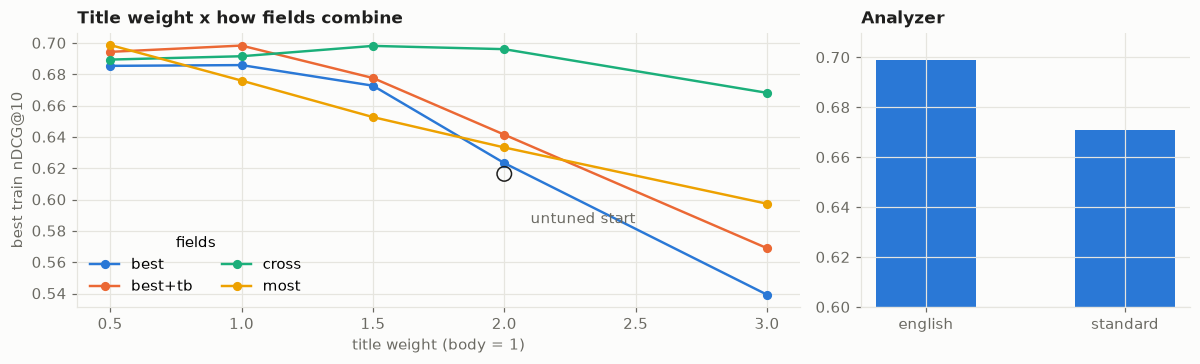

In [5]:
eng = sweep[sweep.analyzer == 'english'].groupby(['query_type', 'title_boost'])['ndcg@10'].max().unstack(0)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3.4), gridspec_kw={'width_ratios': [2.2, 1]})
for k, col in enumerate(['best', 'best+tb', 'cross', 'most']):
    ax1.plot(eng.index, eng[col], marker='o', markersize=5, color=plot.SERIES[k], label=col)
ax1.scatter([2.0], [best['train']['baseline_ndcg@10']], s=90, facecolors='none', edgecolors=plot.INK, zorder=3)
ax1.annotate('untuned start', (2.0, best['train']['baseline_ndcg@10']), xytext=(2.1, 0.585), color=plot.MUTED)
ax1.set_xlabel('title weight (body = 1)'); ax1.set_ylabel('best train nDCG@10')
ax1.set_title('Title weight x how fields combine'); ax1.legend(title='fields', ncol=2, loc='lower left')
an = sweep.groupby('analyzer')['ndcg@10'].max()
ax2.bar(an.index, an.values, color=plot.SERIES[0], width=0.5); ax2.set_ylim(0.6, 0.71)
ax2.set_title('Analyzer')
plt.tight_layout()

**What tuning taught:** the biggest lever was the **title weight**. The untuned query (circled)
counted titles double, so a title match could drown out a body that actually answered the question.
Lowering it to 0.5-1x helps whichever way the fields are combined; `cross_fields` (treat title and
body as one field) is the most forgiving of a heavy title. Stemming (`english`)
added about 0.03. `k1` and `b`, the settings textbooks discuss most, moved the best score by less
than 0.002.

For reference, the published BEIR benchmark reports BM25 at about 0.665 on this test set. The
tuned 0.690 is a little above it, the untuned 0.610 below it.

## 4 · Search-box features beyond ranking

### Typos
We gave every test question one realistic typo ("inductiae" for "inductive") and re-scored, with and
without *fuzzy matching* (`fuzziness: AUTO`: a word may match others 1-2 letters different).

In [6]:
features.build_feature_index()
_, q, rel = beir.load('data/beir/scifact', 'test')
typo_q = features.typo_queries(q)
print('example:', list(typo_q.values())[0])
res = {}
for name, qs in (('clean questions', q), ('one typo each', typo_q)):
    for fuzzy in (False, True):
        res[(name, 'fuzzy on' if fuzzy else 'fuzzy off')] = metrics.score_run(features.run_many(qs, fuzzy=fuzzy), rel, 10)['ndcg@10']
pd.Series(res).unstack().round(3)

example: 0-dimensional biomaterials show inductiae properties.


,fuzzy off,fuzzy on
clean questions,0.690,0.689
one typo each,0.652,0.681


One typo per question costs about 0.04 nDCG. Fuzzy matching wins most of it back, and costs
nothing on correctly spelled questions.

### Highlighting: show *why* a result matched

In [7]:
body = features.query('vitamin D deficiency and bone fractures', k=2, highlight=True)
for h in stack.opensearch().search(index=features.FEATURE_INDEX, body=body)['hits']['hits']:
    print(h['_source']['title']); [print('   ...', f, '...') for f in h['highlight'].get('body', [])]

Vitamin d deficiency in postmenopausal women - biological correlates.
   ... INTRODUCTION Low **vitamin** **D** (VD) is associated with secondary hyperparathyroidism and both contribute to deleterious consequences ...
   ... (reduced **bone** mineral density (BMD), risk of **fractures** and falls). ...
Vitamin D insufficiency and the blunted PTH response in established osteoporosis: the role of magnesium deficiency
   ... **D**, Mg) and **bone** turnover markers (serum CTX & P1CP). ...
   ... In subjects with a low **vitamin** **D** and raised PTH mean retention was 55.9%(14.8) and in the **vitamin** replete group 36.1%(14.4 ...


### Autocomplete (search-as-you-type), and synonyms

In [8]:
for prefix in ('vitamin d def', 'stem ce', 'myocard'):
    print(f'{prefix!r:16} ->', features.autocomplete(prefix, k=3))
syn = metrics.score_run(features.run_many(q, synonyms=True), rel, 10)['ndcg@10']
plain = metrics.score_run(features.run_many(q), rel, 10)['ndcg@10']
print(f'\nsynonyms on: {syn:.4f}   off: {plain:.4f}')

'vitamin d def'  -> ['Vitamin d deficiency in postmenopausal women - biological correlates.', 'Vitamin D: The "sunshine" vitamin.', 'Molecular Mechanisms of Vitamin D Action']
'stem ce'        -> ['Stem Cells,Cancer and Cancer Stem Cells', 'Embryonic stem cells require Wnt proteins to prevent differentiation to epiblast stem cells', 'Stem Cells and Early Lineage Development']
'myocard'        -> ['Interleukin-33 prevents apoptosis and improves survival after experimental myocardial infarction through ST2 signaling.', 'A prospective study of plasma homocyst(e)ine and risk of myocardial infarction in US physicians.', 'Myocardial muscarinic receptor upregulation and normal response to isoproterenol in denervated hearts by familial amyloid polyneuropathy.']

synonyms on: 0.6901   off: 0.6896


**Synonyms made no measurable difference.** Our small medical list ("heart attack" = "myocardial
infarction") rarely appears in these questions. Synonym lists help when they are built from what
real users type and fail to find, not from a guess.

### Explain: why a document got its score

In [9]:
qtext = 'Mesenchymal stem cells repair cartilage'
top = features.run_many({'x': qtext}, k=1)['x'][0]
e = features.explain(qtext, top)['explanation']
print(round(e['value'], 2), e['description'])
for d in e['details'][:4]:
    print('  ', round(d['value'], 2), d['description'][:90])

11.39 sum of:
   1.21 sum of:
   2.36 weight(body:mesenchym in 543) [PerFieldSimilarity], result of:
   1.82 weight(body:stem in 543) [PerFieldSimilarity], result of:
   0.61 weight(body:cell in 543) [PerFieldSimilarity], result of:


## When *not* to use OpenSearch for this

- **Small data and simple needs:** Postgres's any-word search, or a trigram index for typos, may
  be good enough, and it's one less system to run and keep in sync.
- **As the only copy of the data:** no multi-document transactions, and writes take about 1 second
  to become searchable. Here Postgres is the source of truth and `oslab sync` rebuilds the index.
- **Lookups by exact id:** use the database.

**Industry uses:** product and catalog search, documentation and help-centre search, legal and
patent discovery, internal "search everything" portals.